# Round 1 – Data Understanding, Preparation & EDA

## Smart Irrigation Requirement Prediction

This notebook performs the Round 1 analysis on the irrigation dataset.

## 1. Import Libraries

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_selection import f_classif, mutual_info_classif
from sklearn.preprocessing import LabelEncoder

## 2. Load Dataset

In [2]:
df = pd.read_csv("Dataset/train.csv")
df.head()

,id,Soil_Type,Soil_pH,Soil_Moisture,Organic_Carbon,Electrical_Conductivity,Temperature_C,Humidity,Rainfall_mm,Sunlight_Hours,...,Crop_Type,Crop_Growth_Stage,Season,Irrigation_Type,Water_Source,Field_Area_hectare,Mulching_Used,Previous_Irrigation_mm,Region,Irrigation_Need
0,0,Loamy,4.92,32.58,1.01,3.05,15.01,50.61,725.99,5.90,...,Sugarcane,Sowing,Zaid,Drip,Rainwater,0.82,No,112.16,East,Low
1,1,Clay,7.08,56.61,0.44,2.00,22.92,67.86,985.66,6.98,...,Wheat,Vegetative,Kharif,Rainfed,River,5.27,Yes,47.16,South,Low
2,2,Clay,5.69,27.71,0.81,2.83,26.97,92.22,2201.70,6.05,...,Rice,Vegetative,Kharif,Sprinkler,Reservoir,8.24,Yes,110.38,North,Low
3,3,Sandy,5.65,13.32,1.33,0.87,13.32,61.57,1357.33,9.12,...,Wheat,Flowering,Kharif,Canal,River,8.32,Yes,53.85,South,Medium
4,4,Clay,7.96,59.14,0.38,0.96,20.22,91.11,1538.20,6.95,...,Wheat,Sowing,Rabi,Canal,River,7.37,No,93.19,South,Low


## 3. Dataset Shape

In [3]:
print("Dataset Shape:", df.shape)

Dataset Shape: (630000, 21)


## 4. Column Names

In [4]:
df.columns.tolist()

['id',
 'Soil_Type',
 'Soil_pH',
 'Soil_Moisture',
 'Organic_Carbon',
 'Electrical_Conductivity',
 'Temperature_C',
 'Humidity',
 'Rainfall_mm',
 'Sunlight_Hours',
 'Wind_Speed_kmh',
 'Crop_Type',
 'Crop_Growth_Stage',
 'Season',
 'Irrigation_Type',
 'Water_Source',
 'Field_Area_hectare',
 'Mulching_Used',
 'Previous_Irrigation_mm',
 'Region',
 'Irrigation_Need']

## 5. First 5 Rows

In [5]:
df.head()

,id,Soil_Type,Soil_pH,Soil_Moisture,Organic_Carbon,Electrical_Conductivity,Temperature_C,Humidity,Rainfall_mm,Sunlight_Hours,...,Crop_Type,Crop_Growth_Stage,Season,Irrigation_Type,Water_Source,Field_Area_hectare,Mulching_Used,Previous_Irrigation_mm,Region,Irrigation_Need
0,0,Loamy,4.92,32.58,1.01,3.05,15.01,50.61,725.99,5.90,...,Sugarcane,Sowing,Zaid,Drip,Rainwater,0.82,No,112.16,East,Low
1,1,Clay,7.08,56.61,0.44,2.00,22.92,67.86,985.66,6.98,...,Wheat,Vegetative,Kharif,Rainfed,River,5.27,Yes,47.16,South,Low
2,2,Clay,5.69,27.71,0.81,2.83,26.97,92.22,2201.70,6.05,...,Rice,Vegetative,Kharif,Sprinkler,Reservoir,8.24,Yes,110.38,North,Low
3,3,Sandy,5.65,13.32,1.33,0.87,13.32,61.57,1357.33,9.12,...,Wheat,Flowering,Kharif,Canal,River,8.32,Yes,53.85,South,Medium
4,4,Clay,7.96,59.14,0.38,0.96,20.22,91.11,1538.20,6.95,...,Wheat,Sowing,Rabi,Canal,River,7.37,No,93.19,South,Low


## 6. Data Types

In [6]:
df.dtypes

id                           int64
Soil_Type                      str
Soil_pH                    float64
Soil_Moisture              float64
Organic_Carbon             float64
Electrical_Conductivity    float64
Temperature_C              float64
Humidity                   float64
Rainfall_mm                float64
Sunlight_Hours             float64
Wind_Speed_kmh             float64
Crop_Type                      str
Crop_Growth_Stage              str
Season                         str
Irrigation_Type                str
Water_Source                   str
Field_Area_hectare         float64
Mulching_Used                  str
Previous_Irrigation_mm     float64
Region                         str
Irrigation_Need                str
dtype: object

## 7. Missing Value Analysis

In [7]:
missing_values = df.isnull().sum()
missing_values

id                         0
Soil_Type                  0
Soil_pH                    0
Soil_Moisture              0
Organic_Carbon             0
Electrical_Conductivity    0
Temperature_C              0
Humidity                   0
Rainfall_mm                0
Sunlight_Hours             0
Wind_Speed_kmh             0
Crop_Type                  0
Crop_Growth_Stage          0
Season                     0
Irrigation_Type            0
Water_Source               0
Field_Area_hectare         0
Mulching_Used              0
Previous_Irrigation_mm     0
Region                     0
Irrigation_Need            0
dtype: int64

## 8. Duplicate Row Analysis

In [8]:
duplicate_count = df.duplicated().sum()
print("Duplicate Rows:", duplicate_count)

Duplicate Rows: 0


## 9. Target Distribution

Target variable: `Irrigation_Need`

In [9]:
target_distribution = df["Irrigation_Need"].value_counts()
target_distribution

Irrigation_Need
Low       369917
Medium    239074
High       21009
Name: count, dtype: int64

In [10]:
target_percentage = df["Irrigation_Need"].value_counts(normalize=True) * 100
target_percentage

Irrigation_Need
Low       58.716984
Medium    37.948254
High       3.334762
Name: proportion, dtype: float64

## 10. Numerical Feature Identification

In [11]:
numerical_columns = df.select_dtypes(include="number").columns.tolist()

# ID is an identifier, not a meaningful predictive feature
if "id" in numerical_columns:
    numerical_columns.remove("id")

numerical_columns

['Soil_pH',
 'Soil_Moisture',
 'Organic_Carbon',
 'Electrical_Conductivity',
 'Temperature_C',
 'Humidity',
 'Rainfall_mm',
 'Sunlight_Hours',
 'Wind_Speed_kmh',
 'Field_Area_hectare',
 'Previous_Irrigation_mm']

## 11. Outlier Analysis – IQR Method

The formal outlier analysis is performed globally for each numerical feature. No observations are removed based only on the category-specific boxplot dots.

In [12]:
outlier_summary = []

for column in numerical_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = (
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ).sum()

    outlier_percentage = (outliers / len(df)) * 100

    outlier_summary.append({
        "Feature": column,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower_Bound": lower_bound,
        "Upper_Bound": upper_bound,
        "Outlier_Count": outliers,
        "Outlier_Percentage": outlier_percentage
    })

outlier_df = pd.DataFrame(outlier_summary)
outlier_df

,Feature,Q1,Q3,IQR,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Percentage
0,Soil_pH,5.6900,7.27,1.5800,3.32000,9.64000,0,0.0
1,Soil_Moisture,23.3400,51.27,27.9300,-18.55500,93.16500,0,0.0
2,Organic_Carbon,0.6100,1.22,0.6100,-0.30500,2.13500,0,0.0
3,Electrical_Conductivity,0.9300,2.58,1.6500,-1.54500,5.05500,0,0.0
4,Temperature_C,19.5175,34.54,15.0225,-3.01625,57.07375,0,0.0
5,Humidity,45.3900,79.12,33.7300,-5.20500,129.71500,0,0.0
6,Rainfall_mm,954.5700,2054.28,1099.7100,-694.99500,3703.84500,0,0.0
7,Sunlight_Hours,5.7600,9.25,3.4900,0.52500,14.48500,0,0.0
8,Wind_Speed_kmh,5.2800,15.43,10.1500,-9.94500,30.65500,0,0.0
9,Field_Area_hectare,3.8800,11.14,7.2600,-7.01000,22.03000,0,0.0


### Outlier Finding

The global IQR analysis detected zero statistical outliers across the numerical features. Therefore, no observations are removed at this stage.

## 12. Categorical Feature Analysis

In [13]:
categorical_columns = df.select_dtypes(include=["str", "object"]).columns.tolist()

if "Irrigation_Need" in categorical_columns:
    categorical_columns.remove("Irrigation_Need")

print("Categorical Feature Count:", len(categorical_columns))
print("\nCategorical Features:")
print(categorical_columns)

Categorical Feature Count: 8

Categorical Features:
['Soil_Type', 'Crop_Type', 'Crop_Growth_Stage', 'Season', 'Irrigation_Type', 'Water_Source', 'Mulching_Used', 'Region']


In [14]:
for column in categorical_columns:
    print(f"\n{column}:")
    print(df[column].value_counts())


Soil_Type:
Soil_Type
Sandy    166509
Clay     158470
Loamy    156455
Silt     148566
Name: count, dtype: int64

Crop_Type:
Crop_Type
Sugarcane    108910
Rice         106697
Cotton       104645
Maize        104274
Wheat        103005
Potato       102469
Name: count, dtype: int64

Crop_Growth_Stage:
Crop_Growth_Stage
Harvest       167689
Flowering     157563
Vegetative    157246
Sowing        147502
Name: count, dtype: int64

Season:
Season
Kharif    216561
Rabi      208033
Zaid      205406
Name: count, dtype: int64

Irrigation_Type:
Irrigation_Type
Canal        161901
Sprinkler    161400
Rainfed      155607
Drip         151092
Name: count, dtype: int64

Water_Source:
Water_Source
Reservoir      162994
River          159819
Groundwater    154155
Rainwater      153032
Name: count, dtype: int64

Mulching_Used:
Mulching_Used
No     316453
Yes    313547
Name: count, dtype: int64

Region:
Region
South      134809
West       131189
East       126163
Central    123712
North      114127
Name: c

## 13. Descriptive Statistics – Numerical Features

In [15]:
descriptive_statistics = df[numerical_columns].describe().T
descriptive_statistics

,count,mean,std,min,25%,50%,75%,max
Soil_pH,630000.0,6.482497,0.922504,4.80,5.6900,6.44,7.27,8.20
Soil_Moisture,630000.0,37.304482,16.377082,8.00,23.3400,37.75,51.27,64.99
Organic_Carbon,630000.0,0.922858,0.365808,0.30,0.6100,0.91,1.22,1.60
Electrical_Conductivity,630000.0,1.744605,0.952321,0.10,0.9300,1.74,2.58,3.50
Temperature_C,630000.0,26.998166,8.623621,12.00,19.5175,26.96,34.54,42.00
Humidity,630000.0,61.563180,19.708152,25.00,45.3900,61.65,79.12,94.99
Rainfall_mm,630000.0,1462.207566,612.989738,0.38,954.5700,1467.16,2054.28,2499.69
Sunlight_Hours,630000.0,7.513382,1.999322,4.00,5.7600,7.58,9.25,11.00
Wind_Speed_kmh,630000.0,10.375394,5.689458,0.50,5.2800,10.48,15.43,20.00
Field_Area_hectare,630000.0,7.517745,4.218124,0.30,3.8800,7.38,11.14,15.00


## 14. Visualization Setup

In [16]:
os.makedirs("outputs", exist_ok=True)
sns.set_theme(style="whitegrid")

## 15. Target Distribution Visualization

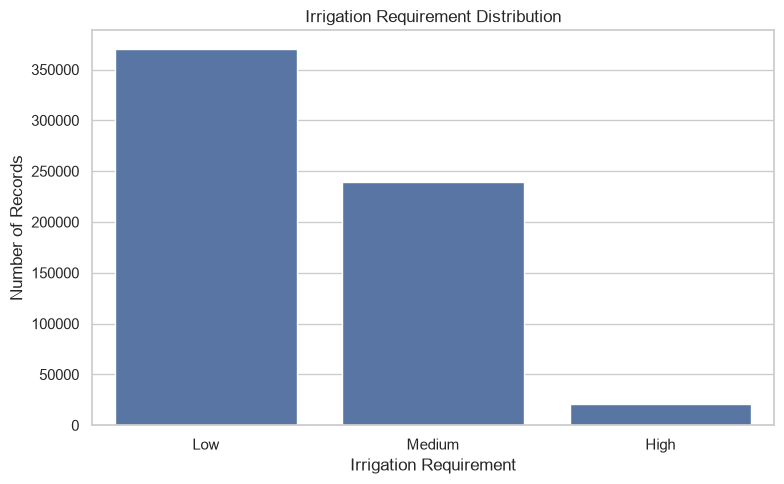

In [17]:
plt.figure(figsize=(8, 5))
sns.countplot(
    data=df,
    x="Irrigation_Need",
    order=["Low", "Medium", "High"]
)
plt.title("Irrigation Requirement Distribution")
plt.xlabel("Irrigation Requirement")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.savefig("outputs/01_target_distribution.png", dpi=150)
plt.show()

## 16. Soil Moisture vs Irrigation Requirement

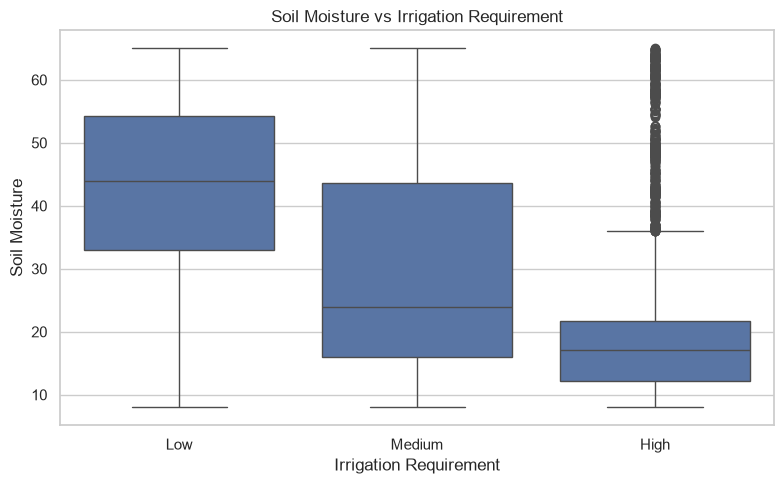

In [18]:
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df,
    x="Irrigation_Need",
    y="Soil_Moisture",
    order=["Low", "Medium", "High"]
)
plt.title("Soil Moisture vs Irrigation Requirement")
plt.xlabel("Irrigation Requirement")
plt.ylabel("Soil Moisture")
plt.tight_layout()
plt.savefig("outputs/02_soil_moisture_vs_irrigation.png", dpi=150)
plt.show()

## 17. Temperature vs Irrigation Requirement

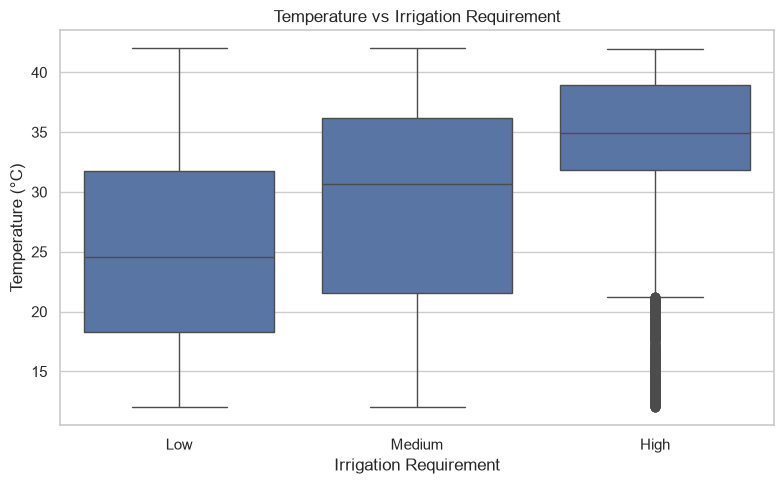

In [19]:
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df,
    x="Irrigation_Need",
    y="Temperature_C",
    order=["Low", "Medium", "High"]
)
plt.title("Temperature vs Irrigation Requirement")
plt.xlabel("Irrigation Requirement")
plt.ylabel("Temperature (°C)")
plt.tight_layout()
plt.savefig("outputs/03_temperature_vs_irrigation.png", dpi=150)
plt.show()

## 18. Rainfall vs Irrigation Requirement

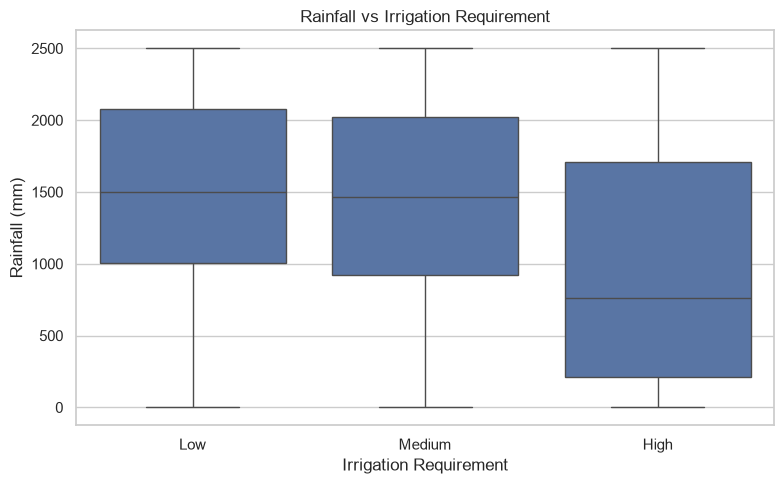

In [20]:
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df,
    x="Irrigation_Need",
    y="Rainfall_mm",
    order=["Low", "Medium", "High"]
)
plt.title("Rainfall vs Irrigation Requirement")
plt.xlabel("Irrigation Requirement")
plt.ylabel("Rainfall (mm)")
plt.tight_layout()
plt.savefig("outputs/04_rainfall_vs_irrigation.png", dpi=150)
plt.show()

## 19. Correlation Heatmap – Numerical Features

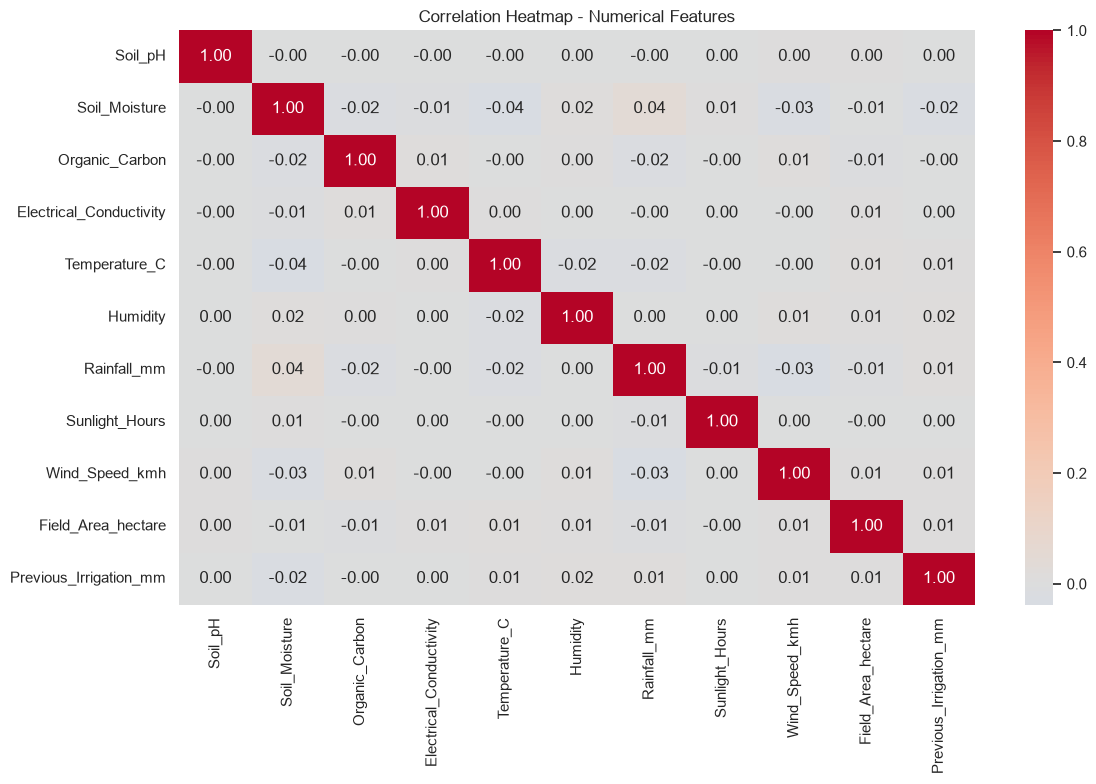

In [21]:
correlation = df[numerical_columns].corr()

plt.figure(figsize=(12, 8))
sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)
plt.title("Correlation Heatmap - Numerical Features")
plt.tight_layout()
plt.savefig("outputs/05_correlation_heatmap.png", dpi=150)
plt.show()

## 20. Feature Relevance Analysis

Numerical features are evaluated using ANOVA F-score and categorical features using Mutual Information.

In [22]:
target_encoder = LabelEncoder()
y_encoded = target_encoder.fit_transform(df["Irrigation_Need"])

### 20.1 Numerical Feature Relevance – ANOVA F-score

In [23]:
X_numeric = df[numerical_columns]

f_scores, p_values = f_classif(X_numeric, y_encoded)

numeric_relevance = pd.DataFrame({
    "Feature": numerical_columns,
    "F_Score": f_scores,
    "P_Value": p_values
})

numeric_relevance = numeric_relevance.sort_values(
    by="F_Score",
    ascending=False
)

numeric_relevance

,Feature,F_Score,P_Value
1,Soil_Moisture,82555.917860,0.000000e+00
8,Wind_Speed_kmh,22514.094175,0.000000e+00
4,Temperature_C,22043.759085,0.000000e+00
6,Rainfall_mm,7241.631185,0.000000e+00
5,Humidity,172.297278,1.558475e-75
0,Soil_pH,158.296161,1.862596e-69
3,Electrical_Conductivity,146.958066,1.555271e-64
10,Previous_Irrigation_mm,137.644058,1.717915e-60
9,Field_Area_hectare,130.155193,3.061912e-57
2,Organic_Carbon,16.167903,9.518080e-08


### 20.2 Categorical Feature Relevance – Mutual Information

In [24]:
X_categorical = df[categorical_columns].copy()

for column in categorical_columns:
    X_categorical[column] = LabelEncoder().fit_transform(
        X_categorical[column]
    )

mi_scores = mutual_info_classif(
    X_categorical,
    y_encoded,
    random_state=42
)

categorical_relevance = pd.DataFrame({
    "Feature": categorical_columns,
    "Mutual_Information": mi_scores
})

categorical_relevance = categorical_relevance.sort_values(
    by="Mutual_Information",
    ascending=False
)

categorical_relevance

,Feature,Mutual_Information
2,Crop_Growth_Stage,0.186111
6,Mulching_Used,0.108966
3,Season,0.027568
4,Irrigation_Type,0.018848
5,Water_Source,0.017911
7,Region,0.016293
0,Soil_Type,0.016034
1,Crop_Type,0.013171


# Round 1 – Summary

The dataset was inspected for structure, data types, missing values, duplicate records, target distribution, statistical outliers, categorical distributions, and descriptive statistics. Exploratory visualizations were generated for the target variable and selected environmental factors. Numerical correlation and feature relevance analysis were also performed.

The resulting visualizations are saved in the `outputs/` directory.